# RQ3: Final Ranking Accuracy
**Research Question 3:** *How accurately does the proposed framework rank candidate requirements relative to the ground-truth priorities?*

To answer this, we first apply the consensus measurement and ranking procedure directly to the RALIC “rated profile” dataset, testing three intuitionistic fuzzification functions (Linear, R-trapezoidal, and Sigmoidal) across varying hesitation degrees ($0.0 \le \pi \le 0.4$).

For each configuration:
1. **Consensus Degree:** Calculated globally across a unified dataset of all requirements.
2. **Classification:** Requirements are mapped to priority classes based on their maximum H-max similarity to the expert-defined Reference Priority Matrix.
3. **Ranking Evaluation:** Requirements are ranked within their respective categories. Tied values receive mean ranks, and **Pearson’s correlation coefficient ($\rho$)** and **Normalized Discounted Cumulative Gain ($\text{nDCG@}k$ at $k \in \{3, 5, 10\}$ and full list)** are computed against the established ground-truth priorities.

Furthermore, to evaluate generalizability and compare our unsupervised IFS ranking model against both simple heuristics and supervised learning-to-rank methods, we benchmark the proposed framework against **Bayesian Personalized Ranking (BPR)**, **SVD Matrix Factorization**, the **Item Mean Heuristic**, and a **Crisp Zero-Hesitation Ablation ($\pi = 0.00$)** across **four empirical datasets**: **RALIC (Levels 1, 2, 3)**, **Pharmacy Information System** ($42 \times 101$), **IES Multi-Criteria** ($5 \times 192 \times 3$), and **MS Word Multi-Criteria** ($4 \times 50 \times 2$).

### 1. Framework Initialization and Analytical Helpers
This section initializes the environment and defines the core analytical helper functions.

In [1]:
# Import core libraries for data manipulation, statistical analysis, and warning control
import os
import time
import numpy as np
import pandas as pd
import scipy.stats as stats
import warnings

# Import custom framework modules and comparative ranking baselines
from src.data_loader import load_ralic, load_pharmacy, load_ies_multicriteria, load_msword_multicriteria
from src.fuzzification import convert_to_ifv_matrix
from src.similarity import get_similarity_matrices
from src.feedback import calculate_final_classification
from src.baselines import predict_item_mean, predict_svd, rank_bpr, rank_from_matrix, calculate_group_ndcg

# Suppress warnings for clean output
warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=stats.ConstantInputWarning)
warnings.filterwarnings('ignore')

BASE_DATA_PATH = '../data/'
RESULTS_PATH = '../results/'
os.makedirs(RESULTS_PATH, exist_ok=True)

# HELPER FUNCTIONS (For Clean Logic)

def get_req_category(req_str, level):
    """Extracts the base category from a requirement based on hierarchy level."""
    if level == 1:
        return 'Project_Objectives'
    elif level == 2:
        return req_str.split('.')[0]  # e.g., 'a.1' -> 'a'
    elif level == 3:
        return '.'.join(req_str.split('.')[:2]) if '.' in req_str else req_str  # e.g., 'a.1.1' -> 'a.1'
    return req_str

def calculate_group_correlation(df_group):
    """Computes the Pearson correlation coefficient for a specific requirement category, handling zero-variance scenarios."""
    valid_df = df_group.dropna(subset=['Predicted_Rank', 'Ground_Truth_Rank_Cat'])

    # Need at least 2 points to calculate correlation
    if len(valid_df) < 2:
        return np.nan

    # If all ranks are tied, variance is 0, correlation is undefined
    if valid_df['Predicted_Rank'].std() == 0 or valid_df['Ground_Truth_Rank_Cat'].std() == 0:
        return np.nan

    return valid_df['Predicted_Rank'].corr(valid_df['Ground_Truth_Rank_Cat'], method='pearson')

### 2. Priority Ranking and Correlation Grid Search
This execution block assesses the final ranking accuracy of the framework. The dataset is unified to compute a global Consensus Degree, after which candidate requirements are classified into priority classes based on their H-max similarity to the expert-defined Reference Priority Matrix. The predicted priorities are subsequently ranked and correlated against the ground truth across multiple fuzzification strategies and hesitation degrees.

In [2]:
# Load Ground Truth Rankings
gt_path = '../data/ralic_ranking.csv'
df_ground_truth = pd.read_csv(gt_path, header=None, names=['Requirement', 'Hierarchy_Level', 'Ground_Truth_Rank'])
df_ground_truth['Requirement'] = df_ground_truth['Requirement'].astype(str).str.strip()

# Define Grid Search Parameters
fuzzification_methods = ['linear', 'r-trapezoidal', 'sigmoidal']
hesitancy_degrees = np.arange(0.0, 0.45, 0.05)

# Initialize and construct the unified dataset to compute the global Consensus Degree
ralic_data = {}
df_list = []

for d_id in [1, 2, 3]:
    df, _, _, expert = load_ralic(data_id=d_id, base_path='../data/')
    ralic_data[d_id] = (df, expert)
    df_list.append(df)

df_unified = pd.concat(df_list, axis=1)
df_unified.columns = [f"Req_{i}" for i in range(df_unified.shape[1])]

results = []
total_start = time.time()

print("Starting RQ3 Ranking Grid Search...")
print("=" * 85)

for method in fuzzification_methods:
    for pi in hesitancy_degrees:

        row_result = {'fuzzification': method, 'uncertainty': round(pi, 2)}

        # Calculate Global Consensus Degree on Unified Dataset
        df_unified_ifv = convert_to_ifv_matrix(df_unified, method=method, pi=pi,
            scale_min=-1.0, scale_max=5.0, trap_limit_min=0.0, trap_limit_max=4.0
        )
        _, sim_unified = get_similarity_matrices(df_unified_ifv)
        row_result['consensus_degree'] = np.nanmean(sim_unified.values)

        # Calculate Ranking Accuracies per Hierarchy Level
        for data_id in [1, 2, 3]:
            df_ralic, df_expert = ralic_data[data_id]

            df_ifv = convert_to_ifv_matrix(df_ralic, method=method, pi=pi,
                scale_min=-1.0, scale_max=5.0, trap_limit_min=0.0, trap_limit_max=4.0
            )
            df_expert_ifv = convert_to_ifv_matrix(df_expert, method=method, pi=0.0,
                scale_min=-1.0, scale_max=5.0
            )

            # Classify candidate requirements into software releases based on the highest Degree of Relation
            classification_df = calculate_final_classification(df_ifv, df_expert_ifv)
            top_release = df_expert_ifv.columns[0]

            if 'Requirement' not in classification_df.columns:
                classification_df = classification_df.reset_index().rename(columns={'index': 'Requirement'})

            # Extract the requirement identifier and its relational similarity to the top priority class
            df_clean = classification_df[['Requirement', top_release]].copy()
            df_clean['Requirement'] = df_clean['Requirement'].astype(str).str.strip()
            df_clean[top_release] = pd.to_numeric(df_clean[top_release], errors='coerce')

            # Merge the derived classifications with the established ground-truth rankings
            df_merged = df_clean.merge(df_ground_truth, on='Requirement', how='inner')
            df_merged['Ground_Truth_Rank'] = pd.to_numeric(df_merged['Ground_Truth_Rank'], errors='coerce')

            df_merged['req_cat'] = df_merged['Requirement'].apply(lambda x: get_req_category(x, data_id))

            # Compute priority ranks within hierarchical categories, assigning mean values for tied relation degrees
            df_merged['Predicted_Rank'] = df_merged.groupby('req_cat')[top_release].rank(ascending=False, method='average')
            df_merged['Ground_Truth_Rank_Cat'] = df_merged.groupby('req_cat')['Ground_Truth_Rank'].rank(ascending=True, method='average')

            category_correlations = df_merged.groupby('req_cat').apply(calculate_group_correlation)
            row_result[f'pearson_result_{data_id}'] = category_correlations.mean()

        results.append(row_result)
        print(f"Processed: {method:<18} | pi: {pi:.2f}")

print("=" * 85)
print(f"Ranking Grid Search Complete in {time.time() - total_start:.2f} seconds.")

# Save results
df_ranking_results = pd.DataFrame(results)
columns_order = ['fuzzification', 'uncertainty', 'consensus_degree', 'pearson_result_1', 'pearson_result_2', 'pearson_result_3']
df_ranking_results = df_ranking_results[columns_order]

# ranking_csv_path = '../results/rq3_ralic_ranking_correlation.csv'
# df_ranking_results.to_csv(ranking_csv_path, index=False)
# print(f"Results successfully saved to '{ranking_csv_path}'.")
display(df_ranking_results.style.format({
        'uncertainty': '{:.2f}',
        'consensus_degree': '{:.3f}',
        'pearson_result_1': '{:.3f}',
        'pearson_result_2': '{:.3f}',
        'pearson_result_3': '{:.3f}'}).hide(axis="index"))

Starting RQ3 Ranking Grid Search...
Processed: linear             | pi: 0.00
Processed: linear             | pi: 0.05
Processed: linear             | pi: 0.10
Processed: linear             | pi: 0.15
Processed: linear             | pi: 0.20
Processed: linear             | pi: 0.25
Processed: linear             | pi: 0.30
Processed: linear             | pi: 0.35
Processed: linear             | pi: 0.40
Processed: r-trapezoidal      | pi: 0.00
Processed: r-trapezoidal      | pi: 0.05
Processed: r-trapezoidal      | pi: 0.10
Processed: r-trapezoidal      | pi: 0.15
Processed: r-trapezoidal      | pi: 0.20
Processed: r-trapezoidal      | pi: 0.25
Processed: r-trapezoidal      | pi: 0.30
Processed: r-trapezoidal      | pi: 0.35
Processed: r-trapezoidal      | pi: 0.40
Processed: sigmoidal          | pi: 0.00
Processed: sigmoidal          | pi: 0.05
Processed: sigmoidal          | pi: 0.10
Processed: sigmoidal          | pi: 0.15
Processed: sigmoidal          | pi: 0.20
Processed: sigmoidal 

fuzzification,uncertainty,consensus_degree,pearson_result_1,pearson_result_2,pearson_result_3
linear,0.00,0.769,0.737,0.553,0.494
linear,0.05,0.764,0.753,0.561,0.494
linear,0.10,0.759,0.753,0.561,0.494
linear,0.15,0.754,0.753,0.561,0.494
linear,0.20,0.749,0.765,0.561,0.494
linear,0.25,0.744,0.772,0.561,0.494
linear,0.30,0.739,0.772,0.561,0.494
linear,0.35,0.734,0.772,0.561,0.494
linear,0.40,0.729,0.772,0.561,0.494
r-trapezoidal,0.00,0.779,0.700,0.487,0.426


### 3. Output and Evaluation Metrics Display
The generated ranking results are loaded and formatted for analytical review. The output highlights the global Consensus Degree alongside the Pearson correlation coefficients for the distinct hierarchy levels.

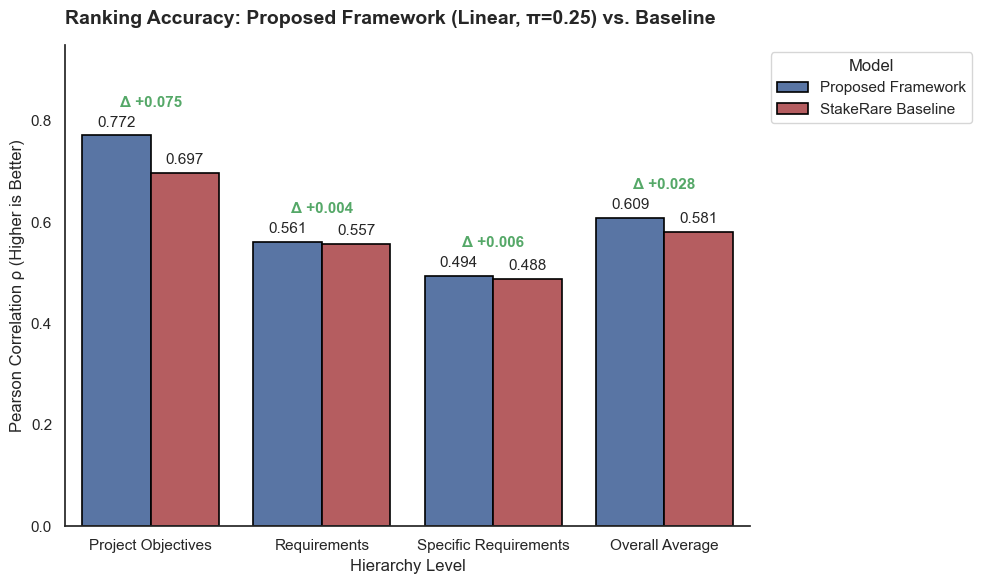

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Define Baselines ---
# StakeRare baselines from literature
stakerare_baselines = {
    'Project Objectives': 0.697,
    'Requirements': 0.557,
    'Specific Requirements': 0.488
}
stakerare_overall = np.mean(list(stakerare_baselines.values()))

# --- 2. Dynamically Find the Best Configuration in the Dataset ---
ranking_csv_path = '../results/rq3_ralic_ranking_correlation.csv'
df_ranking_loaded = pd.read_csv(ranking_csv_path)

# Calculate the overall average Pearson ρ across all 3 levels for each configuration
df_ranking_loaded['overall_avg'] = df_ranking_loaded[['pearson_result_1', 'pearson_result_2', 'pearson_result_3']].mean(axis=1)

# Extract the row with the absolute highest overall average
best_row = df_ranking_loaded.loc[df_ranking_loaded['overall_avg'].idxmax()]

best_method = best_row['fuzzification']
best_pi = best_row['uncertainty']

proposed_values = {
    'Project Objectives': best_row['pearson_result_1'],
    'Requirements': best_row['pearson_result_2'],
    'Specific Requirements': best_row['pearson_result_3']
}
proposed_overall = best_row['overall_avg']

# --- 3. Construct the Plotting DataFrame ---
data = []
levels = ['Project Objectives', 'Requirements', 'Specific Requirements']

for level in levels:
    data.append({'Hierarchy Level': level, 'Model': 'Proposed Framework', 'Pearson ρ': proposed_values[level]})
    data.append({'Hierarchy Level': level, 'Model': 'StakeRare Baseline', 'Pearson ρ': stakerare_baselines[level]})

# Add the overall averages
data.append({'Hierarchy Level': 'Overall Average', 'Model': 'Proposed Framework', 'Pearson ρ': proposed_overall})
data.append({'Hierarchy Level': 'Overall Average', 'Model': 'StakeRare Baseline', 'Pearson ρ': stakerare_overall})

plot_df = pd.DataFrame(data)

# --- 4. Plot Generation ---
# Set visualization style (white background, no grids)
sns.set_theme(style="white")
plt.figure(figsize=(10, 6))

# Define custom colors to match the RQ1 aesthetic
custom_palette = {
    'Proposed Framework': '#4C72B0', # Blue
    'StakeRare Baseline': '#C44E52'  # Red
}

# Generate grouped bar plot
ax = sns.barplot(
    data=plot_df,
    x='Hierarchy Level',
    y='Pearson ρ',
    hue='Model',
    palette=custom_palette,
    edgecolor='black',
    linewidth=1.2,
    errorbar=None
)

# Annotate bars with precise Pearson ρ values
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.3f}',
                    xy=(p.get_x() + p.get_width() / 2, height),
                    xytext=(0, 4),  # 4 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=11)

# Dynamically highlight the differences (Δ) above each group
differences = [
    proposed_values['Project Objectives'] - stakerare_baselines['Project Objectives'],
    proposed_values['Requirements'] - stakerare_baselines['Requirements'],
    proposed_values['Specific Requirements'] - stakerare_baselines['Specific Requirements'],
    proposed_overall - stakerare_overall
]

for i, diff in enumerate(differences):
    # Find the max height between the two bars to place the text securely above them
    proposed_val = data[i*2]['Pearson ρ']
    baseline_val = data[i*2+1]['Pearson ρ']
    max_h = max(proposed_val, baseline_val)

    # Color code the difference (Green for improvement, Red for decrease)
    color = '#55A868' if diff >= 0 else '#C44E52'
    sign = '+' if diff >= 0 else ''

    # Render annotation
    ax.annotate(f'Δ {sign}{diff:.3f}',
                xy=(i, max_h + 0.05), # Offset vertically above the highest bar
                ha='center', va='bottom', fontsize=11, color=color, weight='bold')

# Set title and axes labels dynamically based on the best configuration found
plt.title(f"Ranking Accuracy: Proposed Framework ({best_method.capitalize()}, π={best_pi:.2f}) vs. Baseline",
          fontsize=14, weight='bold', loc='left', pad=15)
plt.ylabel('Pearson Correlation ρ (Higher is Better)', fontsize=12)
plt.xlabel('Hierarchy Level', fontsize=12)

# Increase y-axis limit slightly to make room for the delta annotations
plt.ylim(0, 0.95)

# Move legend outside the plot
plt.legend(title='Model', bbox_to_anchor=(1.02, 1), loc='upper left')

# Remove top and right borders for a cleaner look
sns.despine()

plt.tight_layout()
plt.savefig('../results/rq3_ralic_ranking_comparison.png', dpi=600, bbox_inches='tight')
plt.show()

In [4]:
import pandas as pd

ranking_csv_path = '../results/rq3_ralic_ranking_correlation.csv'
df_ranking_loaded = pd.read_csv(ranking_csv_path)
print("--- Final Ranking Accuracy (Baseline with Unified CD) ---")
display(df_ranking_loaded.style.format({
    'uncertainty': '{:.2f}',
    'consensus_degree': '{:.3f}',
    'pearson_result_1': '{:.3f}',
    'pearson_result_2': '{:.3f}',
    'pearson_result_3': '{:.3f}'
}).hide(axis="index"))

--- Final Ranking Accuracy (Baseline with Unified CD) ---


fuzzification,uncertainty,consensus_degree,pearson_result_1,pearson_result_2,pearson_result_3
linear,0.00,0.769,0.737,0.553,0.494
linear,0.05,0.764,0.753,0.561,0.494
linear,0.10,0.759,0.753,0.561,0.494
linear,0.15,0.754,0.753,0.561,0.494
linear,0.20,0.749,0.765,0.561,0.494
linear,0.25,0.744,0.772,0.561,0.494
linear,0.30,0.739,0.772,0.561,0.494
linear,0.35,0.734,0.772,0.561,0.494
linear,0.40,0.729,0.772,0.561,0.494
r-trapezoidal,0.00,0.779,0.700,0.487,0.426


### 4. Detailed Hierarchy-Level Ranking Output
To examine specific results, this section computes the individual degrees of relation for each candidate requirement, compares the predicted ranks against the ground-truth ranks, and renders a structured output highlighting the Pearson correlation coefficient for each group.

In [5]:
# Edit to get the result for a specific parameter combination
fuzzification_method = 'linear'
hesitancy_degree = 0.25

def display_detailed_configuration(target_method='linear', target_pi=0.20):
    """
    Displays the hierarchy-level ranking details in the requested visual format
    for a specific fuzzification method and uncertainty degree.
    """
    gt_path = '../data/ralic_ranking.csv'
    df_ground_truth = pd.read_csv(gt_path, header=None, names=['Requirement', 'Hierarchy_Level', 'Ground_Truth_Rank'])
    df_ground_truth['Requirement'] = df_ground_truth['Requirement'].astype(str).str.strip()

    print(f"=== Detailed Results | Fuzzification: '{target_method}', Uncertainty (π): {target_pi:.2f} ===")

    overall_pearsons = []

    for data_id in [1, 2, 3]:
        # Extract stakeholder assessments and expert benchmark parameters
        df_ralic, _, _, df_expert = load_ralic(data_id=data_id, base_path='../data/')

        # Construct the Intuitionistic Fuzzy Value matrices for the isolated configuration
        df_ifv = convert_to_ifv_matrix(df_ralic, method=target_method, pi=target_pi,
            scale_min=-1.0, scale_max=5.0, trap_limit_min=0.0, trap_limit_max=4.0
        )
        df_expert_ifv = convert_to_ifv_matrix(df_expert, method=target_method, pi=0.0,
            scale_min=-1.0, scale_max=5.0
        )

        classification_df = calculate_final_classification(df_ifv, df_expert_ifv)
        top_release = df_expert_ifv.columns[0]

        if 'Requirement' not in classification_df.columns:
            classification_df = classification_df.reset_index().rename(columns={'index': 'Requirement'})

        df_clean = classification_df[['Requirement', top_release]].copy()
        df_clean['Requirement'] = df_clean['Requirement'].astype(str).str.strip()
        df_clean[top_release] = pd.to_numeric(df_clean[top_release], errors='coerce')

        df_merged = df_clean.merge(df_ground_truth, on='Requirement', how='inner')
        df_merged['Ground_Truth_Rank'] = pd.to_numeric(df_merged['Ground_Truth_Rank'], errors='coerce')

        df_merged['req_cat'] = df_merged['Requirement'].apply(lambda x: get_req_category(x, data_id))
        df_merged['Predicted_Rank'] = df_merged.groupby('req_cat')[top_release].rank(ascending=False, method='average')
        df_merged['Ground_Truth_Rank_Cat'] = df_merged.groupby('req_cat')['Ground_Truth_Rank'].rank(ascending=True, method='average')

        display_rows = []
        level_rhos = []

        # Group by requirement category and compute the discrete Pearson correlation metrics
        for cat, group in df_merged.sort_values('Requirement').groupby('req_cat', sort=False):
            rho = calculate_group_correlation(group)
            if not np.isnan(rho):
                level_rhos.append(rho)

            # Structure the categorized output format
            for i, (_, row) in enumerate(group.iterrows()):
                req_col_name = 'Project objective' if data_id == 1 else 'Requirement'

                # Isolate the correlation coefficient display to the leading row of each category group
                if i == 0:
                    rho_str = f"{rho:.3f}" if not np.isnan(rho) else "NA"
                else:
                    rho_str = ""

                display_rows.append({
                    req_col_name: row['Requirement'],
                    'Calculated degree of relation': f"{row[top_release]:.3f}",
                    'Calculated ranking': f"{row['Predicted_Rank']:g}",
                    'Ground truth ranking': f"{row['Ground_Truth_Rank_Cat']:g}",
                    "Pearson's ρ": rho_str
                })

        # Aggregate the mean hierarchy-level correlation and append to the evaluation metrics
        level_avg_rho = np.mean(level_rhos) if level_rhos else np.nan
        overall_pearsons.append(level_avg_rho)

        display_rows.append({
            req_col_name: "AVERAGE",
            'Calculated degree of relation': "",
            'Calculated ranking': "",
            'Ground truth ranking': "",
            "Pearson's ρ": f"{level_avg_rho:.3f}" if not np.isnan(level_avg_rho) else "NA"
        })

        # Render styled Dataframe
        df_display = pd.DataFrame(display_rows)
        level_name = {1: 'Project Objectives', 2: 'Requirements', 3: 'Specific Requirements'}[data_id]

        print(f"\n--- {level_name} ---")
        display(df_display.style.hide(axis="index").set_properties(**{'text-align': 'center'}))

    print(f"\n{'='*85}")
    print(f"OVERALL AVERAGE PEARSON'S ρ ACROSS ALL LEVELS: {np.nanmean(overall_pearsons):.3f}")
    print(f"{'='*85}\n")

# Execute the visual output block for the target configuration
display_detailed_configuration(target_method=fuzzification_method, target_pi=hesitancy_degree)

=== Detailed Results | Fuzzification: 'linear', Uncertainty (π): 0.25 ===

--- Project Objectives ---


Project objective,Calculated degree of relation,Calculated ranking,Ground truth ranking,Pearson's ρ
a,0.863,1,1.5,0.772
b,0.220,6,4.5,
c,0.828,4,1.5,
d,0.861,2,3,
e,0.068,10,7,
f,0.136,9,7,
g,0.840,3,4.5,
h,0.552,5,7,
i,0.158,8,10,
j,0.205,7,9,



--- Requirements ---


Requirement,Calculated degree of relation,Calculated ranking,Ground truth ranking,Pearson's ρ
a.1,0.792,2,2,1.000
a.2,0.741,3,3,
a.3,0.846,1,1,
b.1,0.102,2,1,0.857
b.2,0.013,6,4,
b.3,0.120,1,2,
b.4,0.064,3,3,
b.5,0.018,5,6,
b.6,0.034,4,5,
b.7,0.008,7,7,



--- Specific Requirements ---


Requirement,Calculated degree of relation,Calculated ranking,Ground truth ranking,Pearson's ρ
a.1.2,0.792,1.5,nan,NA
a.1.3,0.792,1.5,nan,
a.2,0.741,1,1,NA
a.3.1,0.846,1,1.5,0.969
a.3.2,0.826,2,1.5,
a.3.3,0.811,4,3,
a.3.4,0.814,3,nan,
a.3.6,0.794,5,4,
b.1.1,0.013,5.5,2,0.130
b.1.2,0.039,2,2,



OVERALL AVERAGE PEARSON'S ρ ACROSS ALL LEVELS: 0.609



### 4. Comprehensive Multi-Dataset & Baseline Ranking Evaluation (Pearson's $\rho$ & $\text{nDCG@}k$)
To complement Pearson's $\rho$ with top-weighted ranking metrics that penalize errors at the top of the priority list and remain robust in small requirement subcategories, we compute **Normalized Discounted Cumulative Gain ($\text{nDCG@}3$, $\text{nDCG@}5$, $\text{nDCG@}10$, and $\text{nDCG}_{\text{Full}}$)**.

We benchmark the proposed IFS framework against:
1. **Crisp Variant ($\pi = 0.00$):** Zero-hesitation R-trapezoidal baseline isolating the impact of modeling hesitation ($\pi > 0$).
2. **BPR (Bayesian Personalized Ranking):** Supervised pairwise learning-to-rank model trained via stochastic gradient ascent on observed preference pairs $(r_{u,i} > r_{u,j})$.
3. **SVD Matrix Factorization:** Collective ranking derived from low-rank matrix reconstruction.
4. **Item Mean Heuristic:** Collective ranking derived from mean requirement ratings.

This comparative suite is evaluated across **RALIC (Levels 1, 2, 3)**, **Pharmacy ($42 \times 101$)**, **IES Multi-Criteria ($5 \times 192 \times 3$)**, and **MS Word Multi-Criteria ($4 \times 50 \times 2$)**.

In [6]:
def evaluate_ranking_dataframe(df_scores, df_gt, cat_col=None):
    """Computes Pearson's rho, nDCG@3, nDCG@5, nDCG@10, and Full nDCG against Ground Truth."""

    # Merge derived recommendation rankings with ground-truth records
    merged = df_scores.merge(df_gt, on='Requirement', how='inner')
    if cat_col is None or cat_col not in merged.columns:
        merged['Category'] = 'All'
    else:
        merged['Category'] = merged[cat_col]

    merged['Predicted_Rank'] = merged.groupby('Category')['Release1'].rank(ascending=False, method='average')
    merged['Ground_Truth_Rank_Cat'] = merged.groupby('Category')['Ground_Truth_Rank'].rank(ascending=True, method='average')

    rhos, ndcg3, ndcg5, ndcg10, ndcg_all = [], [], [], [], []

    # Calculate group-level metrics per specific requirement category
    for _, grp in merged.groupby('Category'):
        valid = grp.dropna(subset=['Predicted_Rank', 'Ground_Truth_Rank_Cat'])
        if len(valid) >= 2 and valid['Predicted_Rank'].std() > 0 and valid['Ground_Truth_Rank_Cat'].std() > 0:
            rhos.append(valid['Predicted_Rank'].corr(valid['Ground_Truth_Rank_Cat'], method='pearson'))
        n3 = calculate_group_ndcg(grp, 'Release1', k=3)
        n5 = calculate_group_ndcg(grp, 'Release1', k=5)
        n10 = calculate_group_ndcg(grp, 'Release1', k=10)
        na = calculate_group_ndcg(grp, 'Release1', k=None)

        if not np.isnan(n3): ndcg3.append(n3)
        if not np.isnan(n5): ndcg5.append(n5)
        if not np.isnan(n10): ndcg10.append(n10)
        if not np.isnan(na): ndcg_all.append(na)

    return {
        'Pearson_rho': round(float(np.mean(rhos)), 3) if rhos else np.nan,
        'nDCG@3': round(float(np.mean(ndcg3)), 3) if ndcg3 else np.nan,
        'nDCG@5': round(float(np.mean(ndcg5)), 3) if ndcg5 else np.nan,
        'nDCG@10': round(float(np.mean(ndcg10)), 3) if ndcg10 else np.nan,
        'nDCG_Full': round(float(np.mean(ndcg_all)), 3) if ndcg_all else np.nan
    }


def evaluate_rq3_all():
    """Runs RQ3 ranking comparisons across RALIC, Pharmacy, IES, and MS Word."""
    rows = []

    # --- A. RALIC Hierarchy Levels 1, 2, 3 ---
    gt_ralic = pd.read_csv(os.path.join(BASE_DATA_PATH, 'ralic_ranking.csv'),
                           header=None, names=['Requirement', 'Hierarchy_Level', 'Ground_Truth_Rank'])
    gt_ralic['Requirement'] = gt_ralic['Requirement'].astype(str).str.strip()

    for d_id, level_name in [(1, 'RALIC 1 (Objectives)'), (2, 'RALIC 2 (Requirements)'), (3, 'RALIC 3 (Specific Reqs)')]:
        df_r, _, _, df_exp = load_ralic(data_id=d_id, base_path=BASE_DATA_PATH)
        gt_sub = gt_ralic.copy()
        if d_id == 1:
            gt_sub['req_cat'] = 'Objectives'
        elif d_id == 2:
            gt_sub['req_cat'] = gt_sub['Requirement'].apply(lambda x: x.split('.')[0])
        else:
            gt_sub['req_cat'] = gt_sub['Requirement'].apply(lambda x: '.'.join(x.split('.')[:2]) if '.' in x else x)

        # 1. Proposed IFS (Linear, pi=0.25)
        df_ifv = convert_to_ifv_matrix(df_r, method='linear', pi=0.25, scale_min=-1.0, scale_max=5.0)
        df_exp_ifv = convert_to_ifv_matrix(df_exp, method='linear', pi=0.0, scale_min=-1.0, scale_max=5.0)
        cls_df = calculate_final_classification(df_ifv, df_exp_ifv)[['Requirement', 'Release1']]
        rows.append({'Dataset': level_name, 'Model': 'Proposed IFS (Linear, pi=0.25)',
                     **evaluate_ranking_dataframe(cls_df, gt_sub, cat_col='req_cat')})

        # 2. Crisp Variant (R-trapezoidal, pi=0.00)
        df_ifv0 = convert_to_ifv_matrix(df_r, method='r-trapezoidal', pi=0.00, scale_min=-1.0, scale_max=5.0,
                                        trap_limit_min=0.0, trap_limit_max=4.0)
        df_exp0 = convert_to_ifv_matrix(df_exp, method='r-trapezoidal', pi=0.00, scale_min=-1.0, scale_max=5.0,
                                        trap_limit_min=0.0, trap_limit_max=4.0)
        cls_df0 = calculate_final_classification(df_ifv0, df_exp0)[['Requirement', 'Release1']]
        rows.append({'Dataset': level_name, 'Model': 'Crisp Ablation (pi=0.00)',
                     **evaluate_ranking_dataframe(cls_df0, gt_sub, cat_col='req_cat')})

        # 3. Supervised Pairwise BPR
        bpr_df = rank_bpr(df_r, n_factors=8, n_epochs=60, seed=100)
        rows.append({'Dataset': level_name, 'Model': 'BPR (Supervised Pairwise Rank)',
                     **evaluate_ranking_dataframe(bpr_df, gt_sub, cat_col='req_cat')})

        # 4. SVD Matrix Factorization
        svd_df = rank_from_matrix(predict_svd(df_r, n_factors=3, scale_min=-1.0, scale_max=5.0))
        rows.append({'Dataset': level_name, 'Model': 'SVD Matrix Factorization',
                     **evaluate_ranking_dataframe(svd_df, gt_sub, cat_col='req_cat')})

        # 5. Item Mean Baseline
        im_df = rank_from_matrix(predict_item_mean(df_r, default_val=2.0))
        rows.append({'Dataset': level_name, 'Model': 'Item Mean Heuristic',
                     **evaluate_ranking_dataframe(im_df, gt_sub, cat_col='req_cat')})

    # --- B. Additional Datasets (Pharmacy, IES Multi-Criteria, MS Word Multi-Criteria) ---
    extra_configs = [
        ('Pharmacy (42x101)', load_pharmacy(BASE_DATA_PATH), 1.0, 5.0, 1.5, 4.5, None),
        ('IES Multi-Criteria (5x192x3)', load_ies_multicriteria(BASE_DATA_PATH), 1.0, 5.0, 1.5, 4.5, None),
        ('MS Word Multi-Criteria (4x50x2)', load_msword_multicriteria(BASE_DATA_PATH), 1.0, 9.0, 2.0, 8.0, 'Requirement_Group')
    ]

    for ds_label, loaded_tuple, s_min, s_max, tb, tc, group_col in extra_configs:
        df_d, _, _, km_d, gt_d = loaded_tuple
        top_col = km_d.columns[0]

        # Proposed IFS
        df_ifv = convert_to_ifv_matrix(df_d, method='linear', pi=0.20, scale_min=s_min, scale_max=s_max,
                                       trap_limit_min=tb, trap_limit_max=tc)
        km_ifv = convert_to_ifv_matrix(km_d[[top_col]].rename(columns={top_col: 'Release1'}),
                                       method='linear', pi=0.0, scale_min=s_min, scale_max=s_max)
        cls_df = calculate_final_classification(df_ifv, km_ifv)[['Requirement', 'Release1']]
        rows.append({'Dataset': ds_label, 'Model': 'Proposed IFS (Linear, pi=0.20)',
                     **evaluate_ranking_dataframe(cls_df, gt_d, cat_col=group_col)})

        # BPR
        bpr_df = rank_bpr(df_d, n_factors=5, n_epochs=60, seed=100)
        rows.append({'Dataset': ds_label, 'Model': 'BPR (Supervised Pairwise Rank)',
                     **evaluate_ranking_dataframe(bpr_df, gt_d, cat_col=group_col)})

        # SVD
        svd_df = rank_from_matrix(predict_svd(df_d, n_factors=2, scale_min=s_min, scale_max=s_max))
        rows.append({'Dataset': ds_label, 'Model': 'SVD Matrix Factorization',
                     **evaluate_ranking_dataframe(svd_df, gt_d, cat_col=group_col)})

    # Export consolidated ranking results
    df_rq3_out = pd.DataFrame(rows)
    out_path = os.path.join(RESULTS_PATH, 'rq3_alldatasets_ranking_correlation.csv')
    df_rq3_out.to_csv(out_path, index=False)
    print(f"Saved RQ3 comprehensive ranking results (Pearson rho + nDCG@k) to '{out_path}'.\n")
    return df_rq3_out

print("Running RQ3 Ranking Evaluation (Pearson rho + nDCG@k + BPR)...")
df_rq3_comprehensive = evaluate_rq3_all()

print("--- Comprehensive Ranking Comparison Across Datasets & Baselines ---")
display(df_rq3_comprehensive.style.format({
    'Pearson_rho': '{:.3f}',
    'nDCG@3': '{:.3f}',
    'nDCG@5': '{:.3f}',
    'nDCG@10': '{:.3f}',
    'nDCG_Full': '{:.3f}'
}).hide(axis="index"))

Running RQ3 Ranking Evaluation (Pearson rho + nDCG@k + BPR)...
Saved RQ3 comprehensive ranking results (Pearson rho + nDCG@k) to '../results/rq3_alldatasets_ranking_correlation.csv'.

--- Comprehensive Ranking Comparison Across Datasets & Baselines ---


Dataset,Model,Pearson_rho,nDCG@3,nDCG@5,nDCG@10,nDCG_Full
RALIC 1 (Objectives),"Proposed IFS (Linear, pi=0.25)",0.772,0.913,0.945,0.979,0.979
RALIC 1 (Objectives),Crisp Ablation (pi=0.00),0.700,0.836,0.884,0.929,0.929
RALIC 1 (Objectives),BPR (Supervised Pairwise Rank),0.463,0.757,0.856,0.926,0.926
RALIC 1 (Objectives),SVD Matrix Factorization,0.525,0.913,0.900,0.958,0.958
RALIC 1 (Objectives),Item Mean Heuristic,0.352,0.577,0.740,0.829,0.829
RALIC 2 (Requirements),"Proposed IFS (Linear, pi=0.25)",0.561,0.862,0.923,0.936,0.936
RALIC 2 (Requirements),Crisp Ablation (pi=0.00),0.487,0.854,0.915,0.928,0.928
RALIC 2 (Requirements),BPR (Supervised Pairwise Rank),0.214,0.810,0.897,0.905,0.905
RALIC 2 (Requirements),SVD Matrix Factorization,0.003,0.778,0.870,0.874,0.874
RALIC 2 (Requirements),Item Mean Heuristic,0.101,0.815,0.882,0.885,0.885


### 5.2 Multi-Dataset Ranking Visualization (Pearson's $\rho$ & $\text{nDCG@}5$)
To illustrate generalizability across all six evaluated dataset configurations (RALIC 1–3, Pharmacy, IES Multi-Criteria, and MS Word Multi-Criteria), we generate a two-panel comparison of **(a) Global Rank Correlation (Pearson's $\rho$)** and **(b) Top-Priority Ranking Accuracy ($\text{nDCG@}5$)** for the Proposed IFS framework against supervised pairwise **BPR** and **SVD Matrix Factorization**.

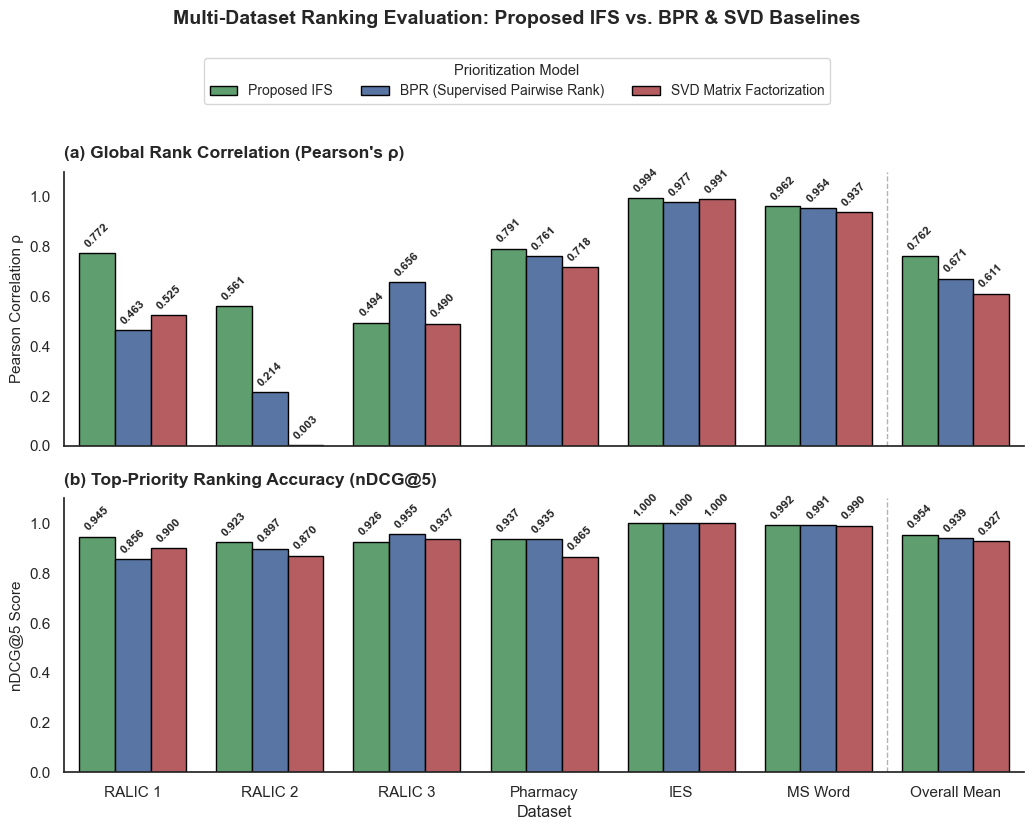

In [7]:
# Filter to the models evaluated across all 6 empirical datasets
df_6 = df_rq3_comprehensive[
    ~df_rq3_comprehensive['Dataset'].isin(['RALIC Average (1–3)', '6-Dataset Average'])
].copy()

df_6['Model_Clean'] = df_6['Model'].apply(lambda x: 'Proposed IFS' if 'Proposed IFS' in str(x) else x)
common_models = ['Proposed IFS', 'BPR (Supervised Pairwise Rank)', 'SVD Matrix Factorization']
df_6 = df_6[df_6['Model_Clean'].isin(common_models)].copy()

# Map dataset names to concise x-axis labels
ds_short_map = {
    'RALIC 1 (Objectives)': 'RALIC 1',
    'RALIC 2 (Requirements)': 'RALIC 2',
    'RALIC 3 (Specific Reqs)': 'RALIC 3',
    'Pharmacy (42x101)': 'Pharmacy',
    'IES Multi-Criteria (5x192x3)': 'IES',
    'MS Word Multi-Criteria (4x50x2)': 'MS Word'
}
df_6['Dataset_Short'] = df_6['Dataset'].map(ds_short_map)

# Compute 6-Dataset Overall Mean
avg_6 = df_6.groupby('Model_Clean', as_index=False)[['Pearson_rho', 'nDCG@5']].mean().round(3)
avg_6['Dataset_Short'] = 'Overall Mean'

df_plot_6 = pd.concat([df_6[['Dataset_Short', 'Model_Clean', 'Pearson_rho', 'nDCG@5']], avg_6], ignore_index=True)
ds_order = ['RALIC 1', 'RALIC 2', 'RALIC 3', 'Pharmacy', 'IES', 'MS Word', 'Overall Mean']

# Set visualization style: Vertically stacked (2 rows, 1 column) for full-width clarity
sns.set_theme(style="white")
fig, axes = plt.subplots(2, 1, figsize=(10.5, 8.2), sharex=True)

custom_palette_6 = {
    'Proposed IFS': '#55A868',                    # Green (Best Overall)
    'BPR (Supervised Pairwise Rank)': '#4C72B0',  # Blue
    'SVD Matrix Factorization': '#C44E52'         # Red
}

# Panel (a): Pearson's rho
ax1 = sns.barplot(
    data=df_plot_6, x='Dataset_Short', y='Pearson_rho', hue='Model_Clean',
    order=ds_order, hue_order=common_models, palette=custom_palette_6,
    edgecolor='black', linewidth=1.0, width=0.78, errorbar=None, ax=axes[0]
)
ax1.set_title("(a) Global Rank Correlation (Pearson's ρ)", fontsize=12.5, weight='bold', loc='left', pad=10)
ax1.set_ylabel("Pearson Correlation ρ", fontsize=11)
ax1.set_xlabel("")
ax1.set_ylim(0.00, 1.10)

# Place a single shared horizontal legend at the top of the figure
handles, labels = ax1.get_legend_handles_labels()
ax1.get_legend().remove()
fig.legend(handles, labels, title='Prioritization Model', loc='upper center',
           bbox_to_anchor=(0.5, 0.96), ncol=3, frameon=True, fontsize=10, title_fontsize=10.5)

for container in ax1.containers:
    ax1.bar_label(container, fmt='%.3f', padding=3, fontsize=8.5, rotation=45, fontweight='bold')

# Panel (b): nDCG@5 (zoomed y-axis [0.75, 1.04] to highlight top-k differences clearly)
ax2 = sns.barplot(
    data=df_plot_6, x='Dataset_Short', y='nDCG@5', hue='Model_Clean',
    order=ds_order, hue_order=common_models, palette=custom_palette_6,
    edgecolor='black', linewidth=1.0, width=0.78, errorbar=None, ax=axes[1]
)
ax2.set_title("(b) Top-Priority Ranking Accuracy (nDCG@5)", fontsize=12.5, weight='bold', loc='left', pad=10)
ax2.set_ylabel("nDCG@5 Score", fontsize=11)
ax2.set_xlabel("Dataset", fontsize=11.5)
ax2.set_ylim(0.00, 1.10)
ax2.get_legend().remove()

for container in ax2.containers:
    ax2.bar_label(container, fmt='%.3f', padding=3, fontsize=8.5, rotation=45, fontweight='bold')

# Add subtle vertical divider before 'Overall Mean'
for ax in axes:
    ax.axvline(x=5.5, color='gray', linestyle='--', linewidth=1.0, alpha=0.6)

sns.despine()
plt.suptitle("Multi-Dataset Ranking Evaluation: Proposed IFS vs. BPR & SVD Baselines",
             fontsize=14, weight='bold', y=1.01)
plt.tight_layout(rect=[0, 0, 1, 0.91])
plt.savefig('../results/rq3_alldatasets_ranking_comparison.png', dpi=600, bbox_inches='tight')
plt.show()